<a href="https://colab.research.google.com/github/Krishanu1711/Machine-Learning/blob/main/Lab-08/A_A1_14%20ML%20Lab-8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC


from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv('ai4i2020.csv')
display(df.head())

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [4]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


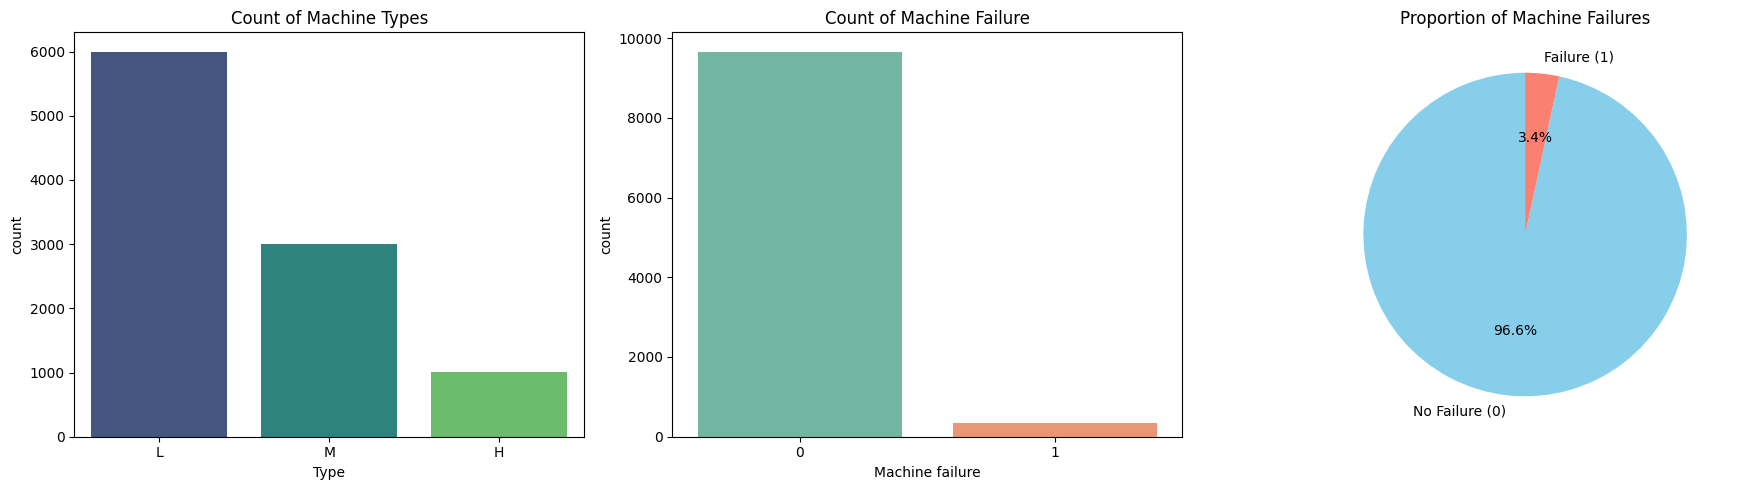

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Countplot for Type
sns.countplot(data=df, x='Type', ax=axes[0], palette='viridis', order=['L', 'M', 'H'])
axes[0].set_title('Count of Machine Types')

# Countplot for Machine failure
sns.countplot(data=df, x='Machine failure', ax=axes[1], palette='Set2')
axes[1].set_title('Count of Machine Failure')

# Pie Chart for Machine failure proportions
failure_counts = df['Machine failure'].value_counts()
axes[2].pie(failure_counts, labels=['No Failure (0)', 'Failure (1)'], autopct='%1.1f%%', colors=['skyblue', 'salmon'], startangle=90)
axes[2].set_title('Proportion of Machine Failures')

plt.tight_layout()
plt.show()

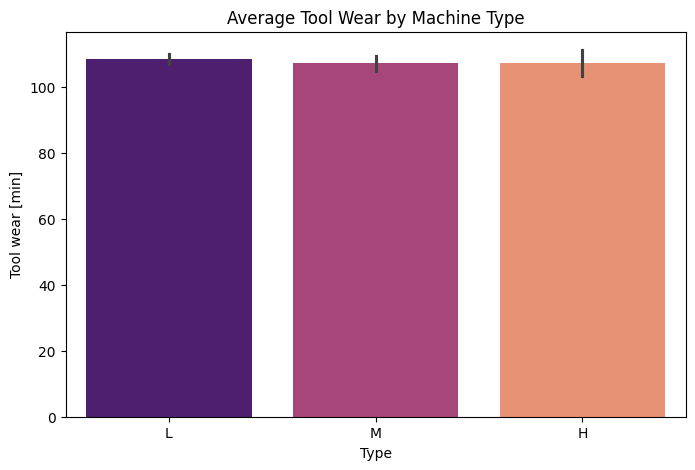

In [6]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Type', y='Tool wear [min]', palette='magma', order=['L', 'M', 'H'])
plt.title('Average Tool Wear by Machine Type')
plt.show()

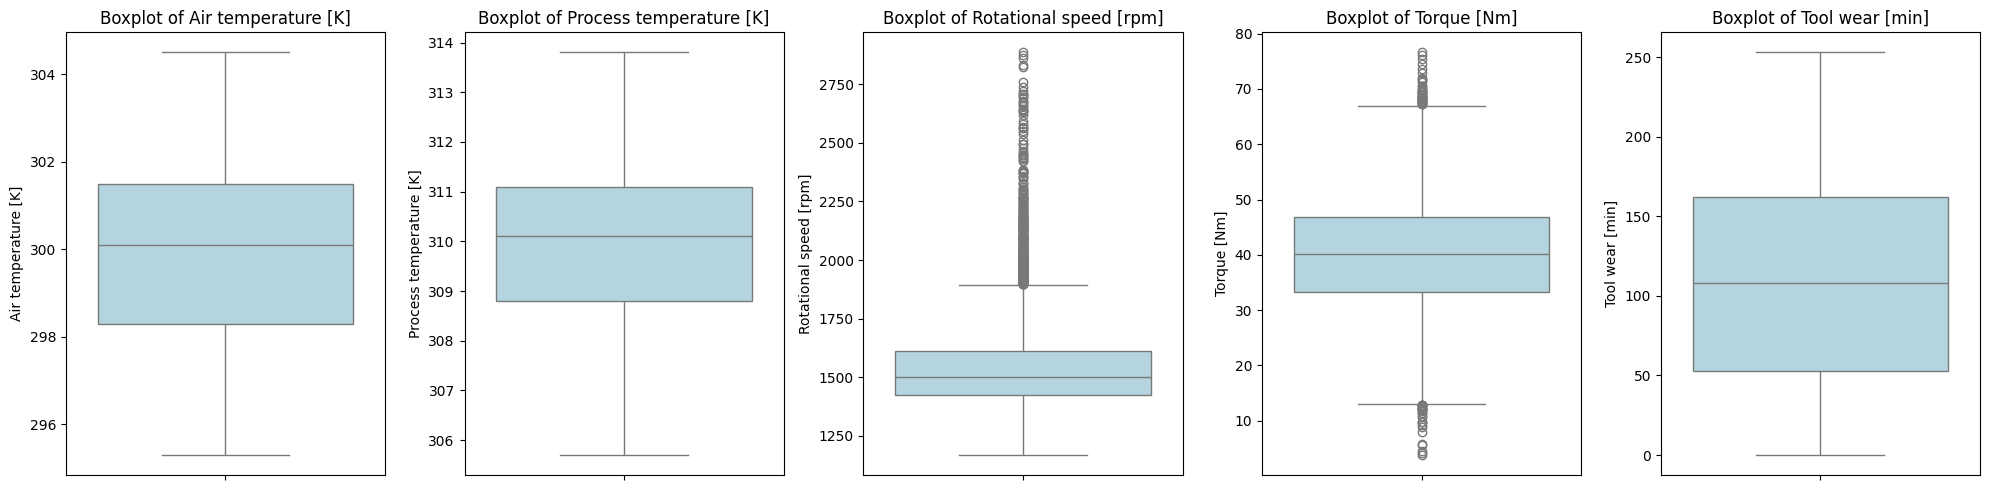

In [7]:
num_features = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i, col in enumerate(num_features):
    sns.boxplot(data=df, y=col, ax=axes[i], color='lightblue')
    axes[i].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

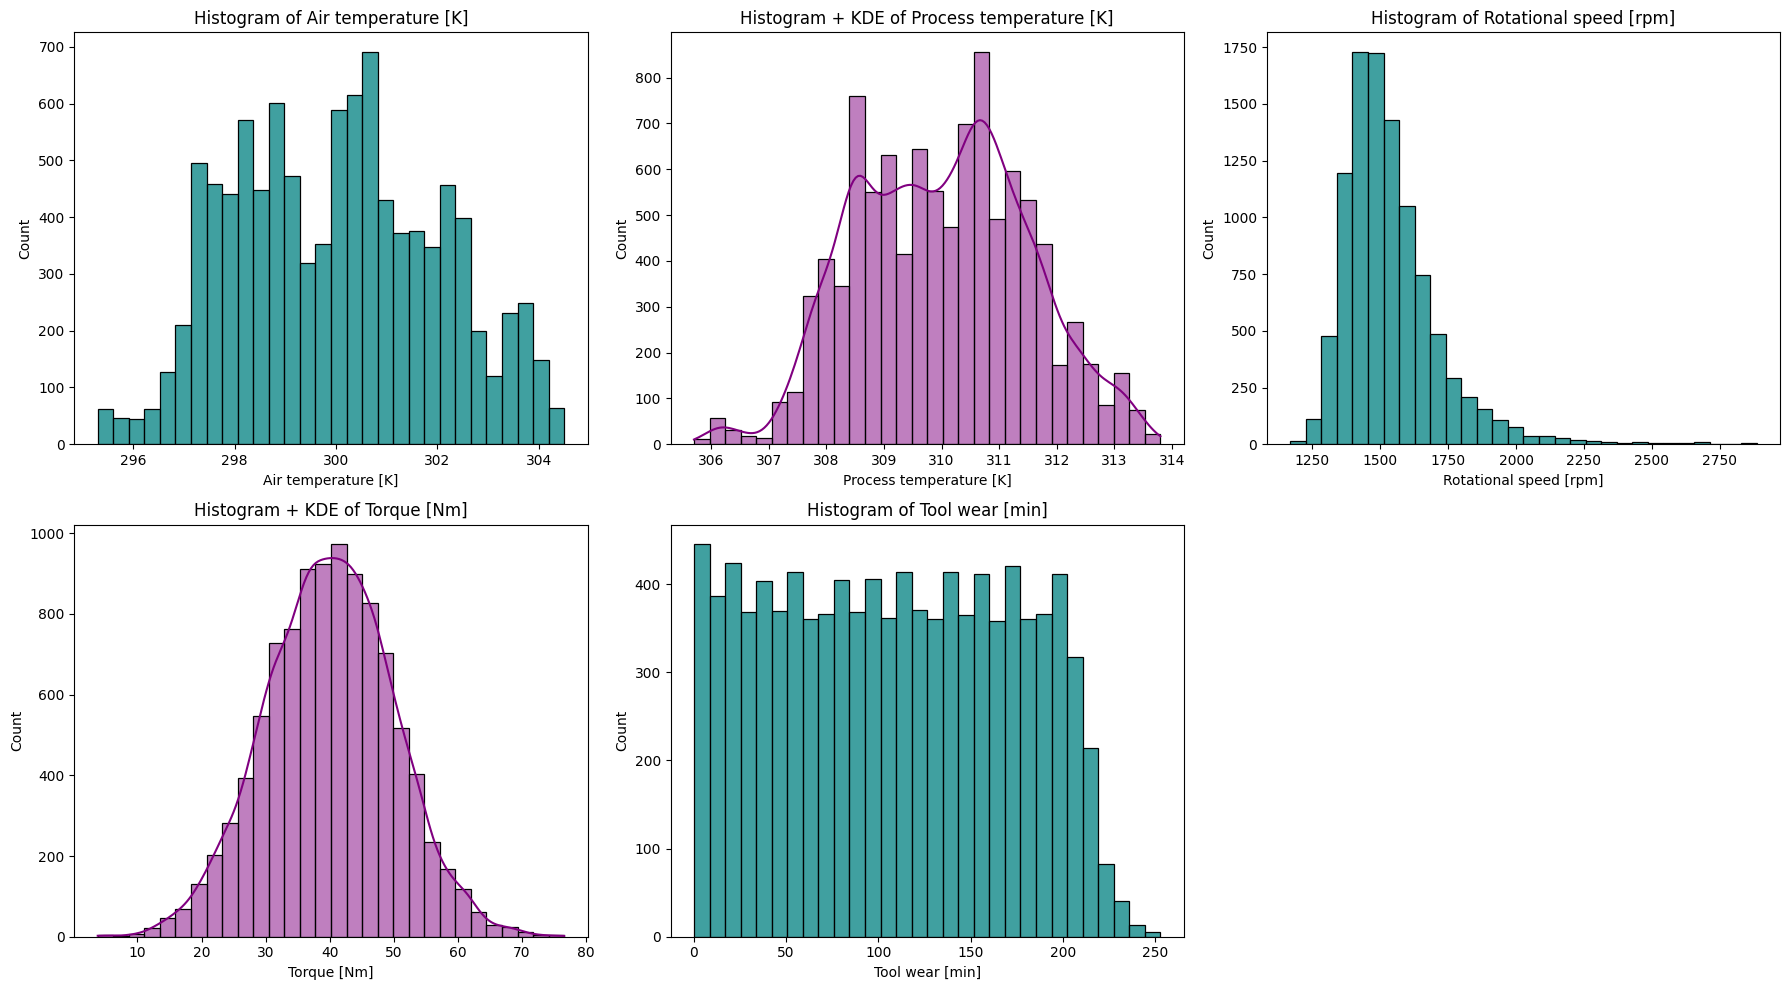

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Plot normal histograms and histograms + KDEs
for i, col in enumerate(num_features):
    if i % 2 == 0:
        # Simple Histogram
        sns.histplot(data=df, x=col, ax=axes[i], bins=30, color='teal')
        axes[i].set_title(f'Histogram of {col}')
    else:
        # Histogram + KDE
        sns.histplot(data=df, x=col, ax=axes[i], bins=30, kde=True, color='purple')
        axes[i].set_title(f'Histogram + KDE of {col}')

# Hide the last empty subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

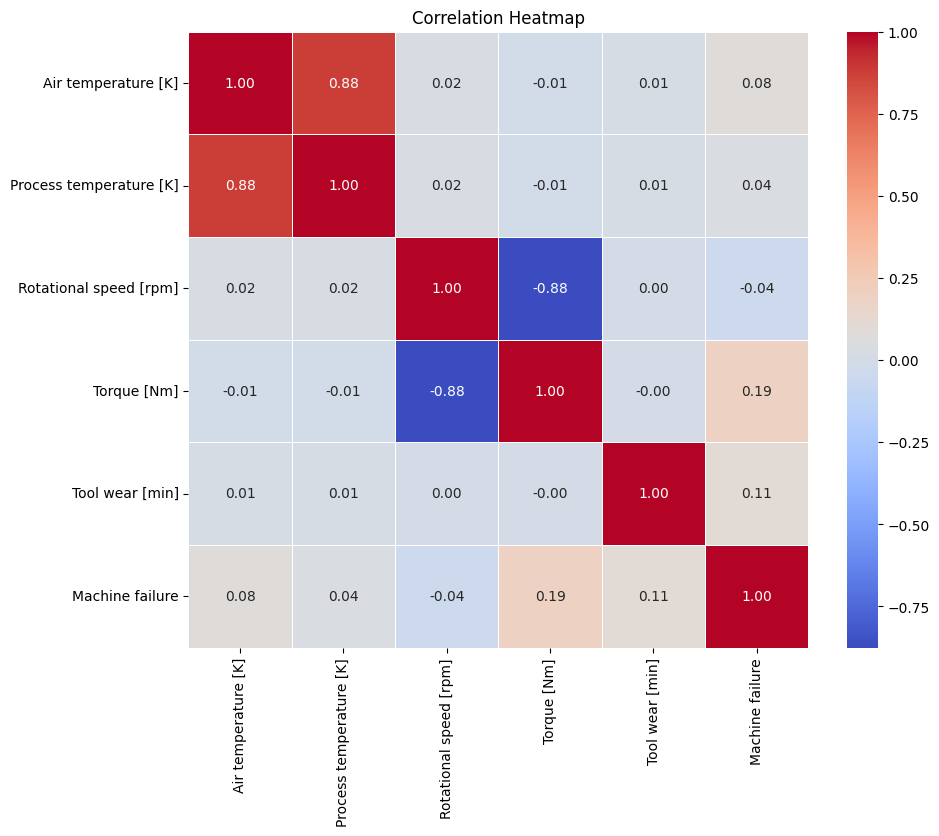

In [9]:
plt.figure(figsize=(10, 8))
numeric_df = df[num_features + ['Machine failure']]
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

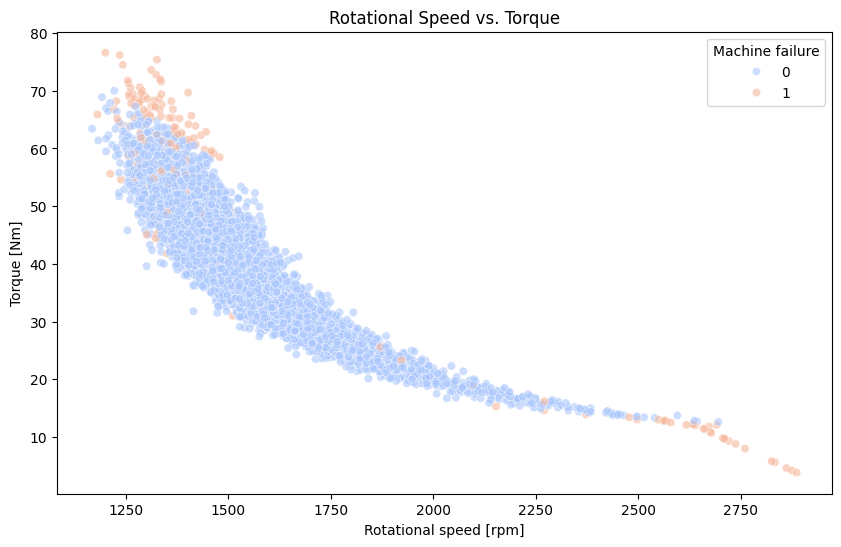

In [10]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Rotational speed [rpm]', y='Torque [Nm]', hue='Machine failure', alpha=0.6, palette='coolwarm')
plt.title('Rotational Speed vs. Torque')
plt.show()

In [11]:
X=df.drop('Machine failure',axis=1)

In [12]:
X=df[[
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]]
y=df["Machine failure"]

In [13]:
print("Input Shape",X.shape)
print("Output Shape",y.shape)

Input Shape (10000, 6)
Output Shape (10000,)


In [14]:
categorical_features=["Type"]
numerical_features=[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [15]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Samples:",X_train.shape[0])
print("Testing Samples:",X_test.shape[0])

Training Samples: 8000
Testing Samples: 2000


In [16]:
preprocessor=ColumnTransformer(
    transformers=[
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features),
        ("num",StandardScaler(),numerical_features)
    ]
)

In [17]:
linear_svm=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",SVC(kernel="linear"))
    ]
)
linear_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type']),
                                                 ('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]'])])),
                ('classifier', SVC(kernel='linear'))])

In [18]:
y_pred_linear=linear_svm.predict(X_test)

In [19]:
accuracy_linear=accuracy_score(y_test,y_pred_linear)
print("Accuracy:",accuracy_linear)
precision_linear=precision_score(y_test,y_pred_linear)
print("Precision:",precision_linear)
recall_linear=recall_score(y_test,y_pred_linear)
print("Recall:",recall_linear)
f1_linear=f1_score(y_test,y_pred_linear)
print("F1 Score:",f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [20]:
print(classification_report(y_test,y_pred_linear,target_names=["NO failure","failure"],zero_division=0))

              precision    recall  f1-score   support

  NO failure       0.97      1.00      0.98      1932
     failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



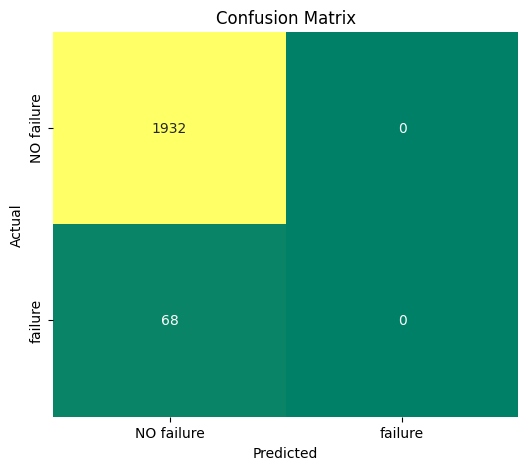

In [21]:
cm_linear=confusion_matrix(y_test,y_pred_linear)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="summer",cbar=False,xticklabels=["NO failure","failure"],yticklabels=["NO failure","failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [22]:
rbf_svm=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",SVC(kernel="rbf"))
    ]
)
rbf_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type']),
                                                 ('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]'])])),
                ('classifier', SVC())])

In [23]:
y_pred_rbf=rbf_svm.predict(X_test)

In [24]:
accuracy_rbf=accuracy_score(y_test,y_pred_rbf)
print("Accuracy:",accuracy_rbf)
precision_rbf=precision_score(y_test,y_pred_rbf)
print("Precision:",precision_rbf)
recall_rbf=recall_score(y_test,y_pred_rbf)
print("recall:",recall_rbf)
f1_rbf=f1_score(y_test,y_pred_rbf)
print("F1:",f1_rbf)

Accuracy: 0.972
Precision: 0.875
recall: 0.20588235294117646
F1: 0.3333333333333333


In [25]:
poly_svm=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",SVC(kernel="poly"))
    ]
)
poly_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type']),
                                                 ('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]'])])),
                ('classifier', SVC(kernel='poly'))])

In [26]:
y_pred_poly=poly_svm.predict(X_test)

In [27]:
accuracy_poly=accuracy_score(y_test,y_pred_poly)
print("Polynomial SVM - Accuracy:",accuracy_poly)
precision_poly=precision_score(y_test,y_pred_poly,zero_division=0)
print("Polynomial SVM - Precision:",precision_poly)
recall_poly=recall_score(y_test,y_pred_poly,zero_division=0)
print("Polynomial SVM - Recall:",recall_poly)
f1_poly=f1_score(y_test,y_pred_poly,zero_division=0)
print("Polynomial SVM - F1 Score:",f1_poly)

print("\nClassification Report:")
print(classification_report(y_test,y_pred_poly,target_names=["NO failure","failure"],zero_division=0))

Polynomial SVM - Accuracy: 0.9745
Polynomial SVM - Precision: 0.8695652173913043
Polynomial SVM - Recall: 0.29411764705882354
Polynomial SVM - F1 Score: 0.43956043956043955

Classification Report:
              precision    recall  f1-score   support

  NO failure       0.98      1.00      0.99      1932
     failure       0.87      0.29      0.44        68

    accuracy                           0.97      2000
   macro avg       0.92      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



In [28]:
sigmoid_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="sigmoid"))
    ]
)
sigmoid_svm.fit(X_train, y_train)
y_pred_sigmoid = sigmoid_svm.predict(X_test)

In [29]:
accuracy_sigmoid = accuracy_score(y_test, y_pred_sigmoid)
print("Sigmoid SVM - Accuracy:", accuracy_sigmoid)
precision_sigmoid = precision_score(y_test, y_pred_sigmoid, zero_division=0)
print("Sigmoid SVM - Precision:", precision_sigmoid)
recall_sigmoid = recall_score(y_test, y_pred_sigmoid, zero_division=0)
print("Sigmoid SVM - Recall:", recall_sigmoid)
f1_sigmoid = f1_score(y_test, y_pred_sigmoid, zero_division=0)
print("Sigmoid SVM - F1 Score:", f1_sigmoid)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_sigmoid, target_names=["NO failure", "failure"], zero_division=0))

Sigmoid SVM - Accuracy: 0.945
Sigmoid SVM - Precision: 0.15
Sigmoid SVM - Recall: 0.1323529411764706
Sigmoid SVM - F1 Score: 0.140625

Classification Report:
              precision    recall  f1-score   support

  NO failure       0.97      0.97      0.97      1932
     failure       0.15      0.13      0.14        68

    accuracy                           0.94      2000
   macro avg       0.56      0.55      0.56      2000
weighted avg       0.94      0.94      0.94      2000



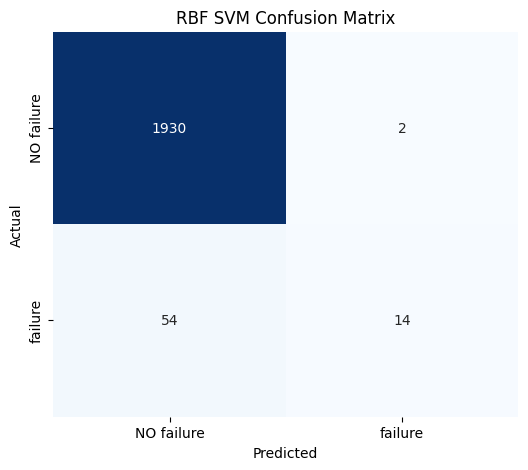

In [30]:
# 1. RBF SVM Confusion Matrix
cm_rbf = confusion_matrix(y_test, y_pred_rbf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rbf, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["NO failure", "failure"], yticklabels=["NO failure", "failure"])
plt.title("RBF SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

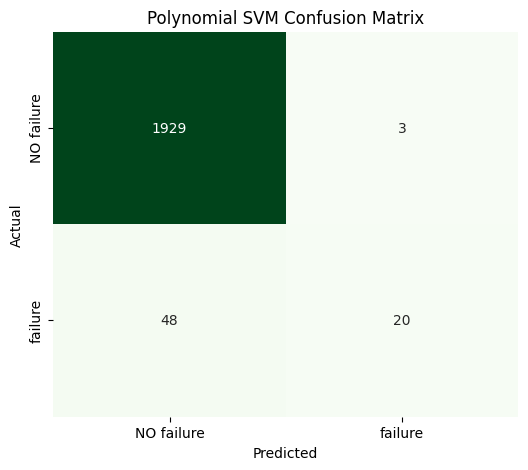

In [31]:
# 2. Polynomial SVM Confusion Matrix
cm_poly = confusion_matrix(y_test, y_pred_poly)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_poly, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["NO failure", "failure"], yticklabels=["NO failure", "failure"])
plt.title("Polynomial SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

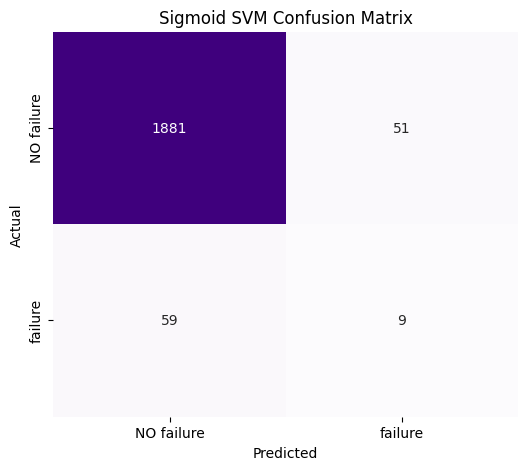

In [32]:
# 3. Sigmoid SVM Confusion Matrix
cm_sigmoid = confusion_matrix(y_test, y_pred_sigmoid)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_sigmoid, annot=True, fmt="d", cmap="Purples", cbar=False,
            xticklabels=["NO failure", "failure"], yticklabels=["NO failure", "failure"])
plt.title("Sigmoid SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [33]:
comparison=pd.DataFrame({
    "Kernel":["Linear SVM","RBF SVM","Polynomial SVM","Sigmoid SVM"],
    "Accuracy":[accuracy_linear,accuracy_rbf,accuracy_poly,accuracy_sigmoid],
    "Precision":[precision_linear,precision_rbf,precision_poly,precision_sigmoid],
    "Recall":[recall_linear,recall_rbf,recall_poly,recall_sigmoid],
    "F1 Score":[f1_linear,f1_rbf,f1_poly,f1_sigmoid]
})
comparison

,Kernel,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.9660,0.000000,0.000000,0.000000
1,RBF SVM,0.9720,0.875000,0.205882,0.333333
2,Polynomial SVM,0.9745,0.869565,0.294118,0.439560
3,Sigmoid SVM,0.9450,0.150000,0.132353,0.140625


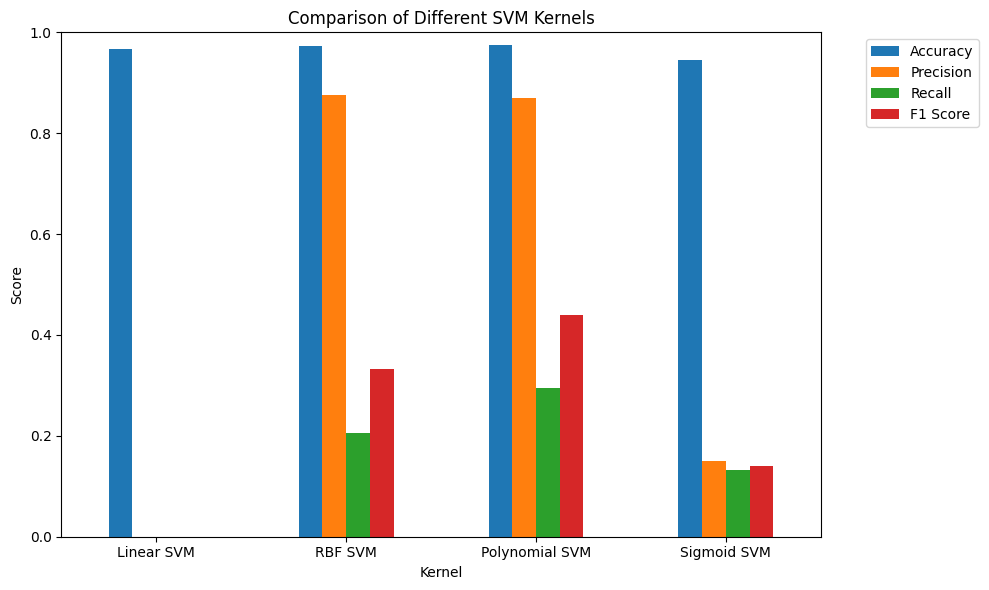

In [34]:
comparison_plot=comparison.set_index("Kernel")
comparison_plot.plot(kind="bar",figsize=(10,6))
plt.title("Comparison of Different SVM Kernels")
plt.ylabel("Score")
plt.xlabel("Kernel")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05,1.0),loc="upper left")
plt.tight_layout()
plt.show()

In [35]:
pipeline = Pipeline(steps=[("preprocessor", preprocessor),
                           ("classifier", SVC(max_iter=20000, cache_size=1000))])

In [36]:
param_grid = [
    {"classifier__kernel": ["linear"], "classifier__C": [0.1, 1, 10]},
    {"classifier__kernel": ["rbf"], "classifier__C": [0.1, 1, 10, 100],
     "classifier__gamma": ["scale", 0.01, 0.1, 1]},
    {"classifier__kernel": ["poly"], "classifier__C": [0.1, 1],
     "classifier__gamma": ["scale", 0.1], "classifier__degree": [2, 3]},
    {"classifier__kernel": ["sigmoid"], "classifier__C": [0.1, 1, 10],
     "classifier__gamma": ["scale", 0.01, 0.1]},
]

In [37]:
# Re-initialize GridSearchCV with the correct pipeline and parameter grid
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

In [38]:
# Fit the grid search estimator using the training data
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['Type']),
                                                                        ('num',
                                                                         StandardScaler(),
                                                                         ['Air '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Process '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]'])])),
                                       ('classifier',
                                        SVC(cache_size=1000, max_iter=20000))]),
             n_job...
                          'classifier__kernel': ['linear']},
                         {'classifier__C': [0.1, 1, 10, 100],
                          'classifier__gamma': ['scale', 0.01, 0.1, 1],
                          'classifier__kernel': ['rbf']},
                         {'classifier__C': [0.1, 1],
                          'classifier__degree': [2, 3],
                          'classifier__gamma': ['scale', 0.1],
                          'classifier__kernel': ['poly']},
                         {'classifier__C': [0.1, 1, 10],
                          'classifier__gamma': ['scale', 0.01, 0.1],
                          'classifier__kernel': ['sigmoid']}],
             scoring='f1', verbose=1)

In [40]:
print("Best Parameters Found:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", grid_search.best_score_)
best_model = grid_search.best_estimator_

Best Parameters Found: {'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Best Cross-Validation F1 Score: 0.7080372186703207


In [41]:
y_pred_best = best_model.predict(X_test)

accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best, zero_division=0)
recall_best = recall_score(y_test, y_pred_best, zero_division=0)
f1_best = f1_score(y_test, y_pred_best, zero_division=0)

print("Best Model Evaluation on Test Set:")
print(f"Accuracy:  {accuracy_best:.4f}")
print(f"Precision: {precision_best:.4f}")
print(f"Recall:    {recall_best:.4f}")
print(f"F1 Score:  {f1_best:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best, target_names=["NO failure", "failure"], zero_division=0))

Best Model Evaluation on Test Set:
Accuracy:  0.9800
Precision: 0.7593
Recall:    0.6029
F1 Score:  0.6721

Classification Report:
              precision    recall  f1-score   support

  NO failure       0.99      0.99      0.99      1932
     failure       0.76      0.60      0.67        68

    accuracy                           0.98      2000
   macro avg       0.87      0.80      0.83      2000
weighted avg       0.98      0.98      0.98      2000



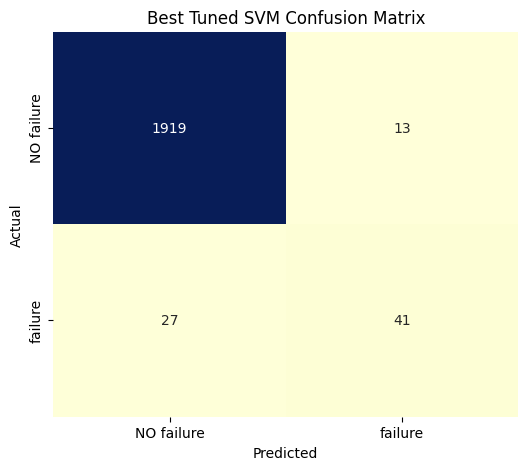

In [42]:
# Plot the Confusion Matrix for the best model
cm_best = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="YlGnBu", cbar=False,
            xticklabels=["NO failure", "failure"], yticklabels=["NO failure", "failure"])
plt.title("Best Tuned SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()